sin xG de StatsBomb: 0


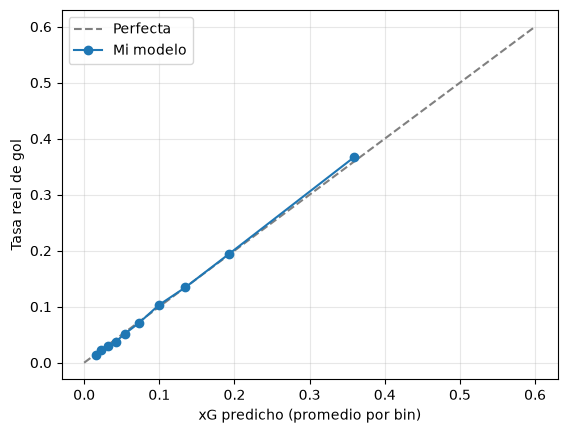

Mi modelo  log loss 0.2776 | Brier 0.0797 | AUC 0.7832
StatsBomb  log loss 0.2660 | Brier 0.0753 | AUC 0.8048


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from xgboost import XGBClassifier

from xg.features import BOOLEAN, CATEGORICAL, NUMERIC
from xg.train import build_pipeline

df = pd.read_parquet("../data/shots_curated.parquet")
raw = pd.read_parquet("../data/shots_raw.parquet", columns=["id", "shot_statsbomb_xg"])
df = df.merge(raw, on="id", how="left")
print("sin xG de StatsBomb:", df["shot_statsbomb_xg"].isna().sum())

y, groups = df["target"], df["match_id"]
X = df.drop(columns=["target", "id", "match_id", "shot_statsbomb_xg"])

xgb = build_pipeline(
    XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03,
                  subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                  reg_lambda=5, random_state=42, eval_metric="logloss"),
    NUMERIC, BOOLEAN, CATEGORICAL,
)
p = cross_val_predict(xgb, X, y, groups=groups, cv=GroupKFold(5),
                      method="predict_proba")[:, 1]

# Curva de calibración
frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
plt.plot([0, 0.6], [0, 0.6], "--", color="gray", label="Perfecta")
plt.plot(mean_pred, frac_pos, "o-", label="Mi modelo")
plt.xlabel("xG predicho (promedio por bin)")
plt.ylabel("Tasa real de gol")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Comparación contra StatsBomb, solo en tiros que tienen su xG
m = df["shot_statsbomb_xg"].notna()
for name, pred in [("Mi modelo", p[m]), ("StatsBomb", df.loc[m, "shot_statsbomb_xg"])]:
    print(f"{name:10s} log loss {log_loss(y[m], pred):.4f} | "
          f"Brier {brier_score_loss(y[m], pred):.4f} | AUC {roc_auc_score(y[m], pred):.4f}")

In [5]:
# guarda la gráfica para el README
plt.savefig("../docs/calibration.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>